<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockLR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
Rows: 332 | Train: 215 | Validation: 50 | Test: 67
Class counts (train): {0: 123, 1: 92}
Class counts (validation): {0: 29, 1: 21}
Class counts (test): {0: 39, 1: 28}
Automatic class weights: {0: np.float64(0.8739837398373984), 1: np.float64(1.1684782608695652)}
Validation balanced accuracy: 0.7906
Selected validation threshold: 0.340

TEST METRICS
Accuracy             0.701493
Balanced_Accuracy    0.718407
Precision            0.605263
Recall               0.821429
F1                   0.696970
Threshold            0.340000
ROC_AUC              0.785714
PR_AUC               0.757713
dtype: float64

Confusion matrix:
 [[24 15]
 [ 5 23]]

Classification report:
               precision    recall  f1-score   support

           0       0.83      0.62      0.71        39
           1       0.61      0.82      0.70        28

    accuracy                           0.70        67
   macro avg       0.72      0.72      0.70        67
weighted avg       0.73      0.7

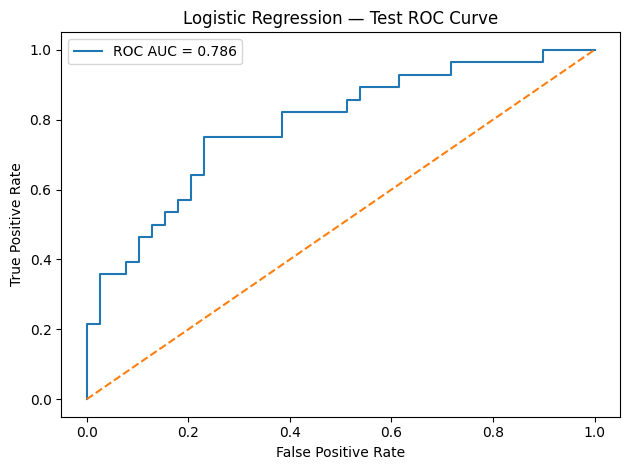

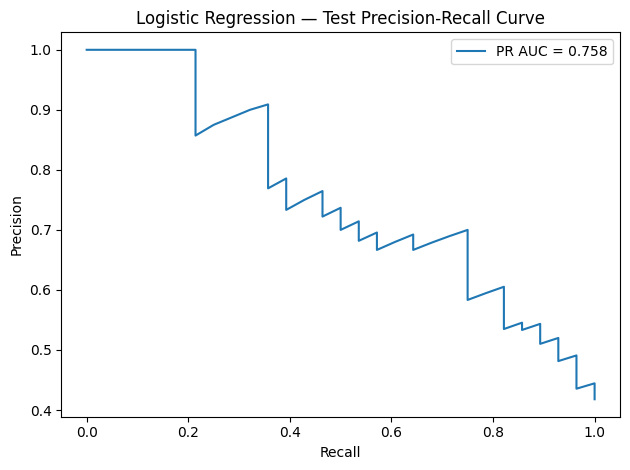

Saved results to: /content/drive/MyDrive/LR_results


In [2]:

# ============================================================
# LOGISTIC REGRESSION — HANCOCK HPV CLASSIFIER
# Shared data preparation | Seed 42 | No SMOTE
# ============================================================

import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

drive.mount("/content/drive")

# ------------------------------------------------------------
# 1. LOAD AND PREPARE THE SAME DATA USED BY GPT-2
# ------------------------------------------------------------

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "LR_results")
os.makedirs(OUT_DIR, exist_ok=True)

def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)
    raise ValueError(f"Cannot read table from {path}")

clinical = load_json_table(os.path.join(BASE, "clinical_data.json"))
pathology = load_json_table(os.path.join(BASE, "pathological_data.json"))

if "patient_id" not in clinical or "patient_id" not in pathology:
    raise KeyError("Both files must contain patient_id.")

df = clinical.merge(
    pathology, on="patient_id", how="left", suffixes=("", "_path")
)

target_candidates = ["hpv_association_p16", "hpv_association_p16_path"]
target_col = next((c for c in target_candidates if c in df.columns), None)
if target_col is None:
    raise KeyError(f"Target not found. Available columns: {df.columns.tolist()}")

feature_candidates = {
    "age_at_initial_diagnosis": ["age_at_initial_diagnosis"],
    "sex": ["sex"],
    "smoking_status": ["smoking_status"],
    "primary_tumor_site": ["primary_tumor_site"],
    "primarily_metastasis": ["primarily_metastasis"],
    "pN_stage": ["pN_stage", "pN_stage_path", "pathological_N_stage",
                 "pathologic_N_stage", "pathological_n_stage"]
}
resolved = {}
for name, candidates in feature_candidates.items():
    match = next((c for c in candidates if c in df.columns), None)
    if match is None:
        raise KeyError(f"Missing predictor {name}; checked {candidates}")
    resolved[name] = match

df = df.rename(columns={v: k for k, v in resolved.items() if v != k})
features = list(feature_candidates.keys())

def normalize_label(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    if value in {"negative", "neg", "0", "false", "no"}:
        return 0
    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1
    try:
        number = float(value)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[["patient_id"] + features + ["HPV_Label"]].copy()

# Match GPT-2's two-stage stratified split exactly.
train_val, test = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["HPV_Label"]
)
train, val = train_test_split(
    train_val, test_size=0.1875, random_state=SEED,
    stratify=train_val["HPV_Label"]
)

print("Rows:", len(df), "| Train:", len(train), "| Validation:", len(val), "| Test:", len(test))
print("Class counts (train):", train["HPV_Label"].value_counts().sort_index().to_dict())
print("Class counts (validation):", val["HPV_Label"].value_counts().sort_index().to_dict())
print("Class counts (test):", test["HPV_Label"].value_counts().sort_index().to_dict())

# Impute using training data only; categorical predictors are one-hot encoded.
numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [c for c in features if c not in numeric_features]

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder)
    ]), categorical_features)
])

X_train = preprocessor.fit_transform(train[features])
X_val = preprocessor.transform(val[features])
X_test = preprocessor.transform(test[features])
y_train = train["HPV_Label"].to_numpy()
y_val = val["HPV_Label"].to_numpy()
y_test = test["HPV_Label"].to_numpy()

# Automatic inverse-frequency class weighting; no SMOTE.
counts = np.bincount(y_train, minlength=2)
class_weights = {i: len(y_train) / (2 * counts[i]) for i in range(2)}
print("Automatic class weights:", class_weights)

# ------------------------------------------------------------
# 2. TRAIN AND SELECT THRESHOLD USING VALIDATION ONLY
# ------------------------------------------------------------

model = LogisticRegression(
    class_weight="balanced", max_iter=2000, random_state=SEED
)
model.fit(X_train, y_train)

val_prob = model.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0.10, 0.90, 161)
threshold_scores = [
    balanced_accuracy_score(y_val, (val_prob >= t).astype(int))
    for t in thresholds
]
best_score = max(threshold_scores)
best_threshold = min(
    (t for t, s in zip(thresholds, threshold_scores) if s == best_score),
    key=lambda t: abs(t - 0.5)
)
print(f"Validation balanced accuracy: {best_score:.4f}")
print(f"Selected validation threshold: {best_threshold:.3f}")

# ------------------------------------------------------------
# 3. FINAL TEST EVALUATION AND SAVE OUTPUTS
# ------------------------------------------------------------

test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

def calculate_metrics(y, prob, pred):
    result = {
        "Accuracy": accuracy_score(y, pred),
        "Balanced_Accuracy": balanced_accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Threshold": best_threshold
    }
    result["ROC_AUC"] = roc_auc_score(y, prob) if len(np.unique(y)) == 2 else np.nan
    result["PR_AUC"] = average_precision_score(y, prob) if len(np.unique(y)) == 2 else np.nan
    return result

metrics = calculate_metrics(y_test, test_prob, test_pred)
print("\nTEST METRICS")
print(pd.Series(metrics))
print("\nConfusion matrix:\n", confusion_matrix(y_test, test_pred))
print("\nClassification report:\n",
      classification_report(y_test, test_pred, zero_division=0))

pd.DataFrame([metrics]).to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
pd.DataFrame({
    "patient_id": test["patient_id"].to_numpy(),
    "y_true": y_test, "probability_positive": test_prob,
    "prediction": test_pred
}).to_csv(os.path.join(OUT_DIR, "test_predictions.csv"), index=False)

with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump({
        "model": "Logistic Regression", "seed": SEED,
        "features": features, "target_column": target_col,
        "threshold": float(best_threshold),
        "class_weight": "balanced", "smote": False,
        "split": {"train": len(train), "validation": len(val), "test": len(test)}
    }, f, indent=2)

if len(np.unique(y_test)) == 2:
    fpr, tpr, _ = roc_curve(y_test, test_prob)
    plt.figure()
    plt.plot(fpr, tpr, label=f"ROC AUC = {metrics['ROC_AUC']:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Logistic Regression — Test ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "roc_curve.png"), dpi=150)
    plt.show()

    precision, recall, _ = precision_recall_curve(y_test, test_prob)
    plt.figure()
    plt.plot(recall, precision, label=f"PR AUC = {metrics['PR_AUC']:.3f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Logistic Regression — Test Precision-Recall Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "pr_curve.png"), dpi=150)
    plt.show()

print("Saved results to:", OUT_DIR)
